# Diffusion Paper Recreation 1D Version
Recreating the 2D Diffusionmodedl from [HuggingFace](https://huggingface.co/blog/annotated-diffusion) as a 1D Version for electricity timeseries.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
from src.Diffusion1d import *
from src.trainloop import *
import numpy as np
import pandas as pd
from ema_pytorch import EMA
import wandb
wandb.login()
device = "cuda" if torch.cuda.is_available() else "cpu"

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\Samuel\_netrc.
wandb: Currently logged in as: natusvictus (natusvictus-fh-aachen-university-of-applied-sciences) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [2]:
# K = 60
# run_id, path = train_run_ids[-1], train_files[-1]
#
# def make_ds(**over):
#     kw = dict(
#         files=[path], rund_ids=[run_id],
#         gen_cols=TARGET_COLS, cond_cols=DYNAMIC_COND_COLS,
#         window_length=WINDOW_LENGTH, stride=STRIDE,
#         target_scaler=target_scaler, condition_scaler=condition_scaler,
#         static_by_run_id=train_static, resolution=RESOLUTION,
#         shufflefiles=False, shufflewindows=False, buffer_size=0,   # deterministic, in order
#         aggregation=TS_AGG,
#         target_norm=build_norm_factors(train_df, TARGET_COLS, NORM_BY_COL),
#         condition_norm=build_norm_factors(train_df, DYNAMIC_COND_COLS, NORM_BY_COL),
#         context_steps=K, context_dropout=0.0, context_noise=0.0,
#     )
#     kw.update(over)
#     return h5Dataset(**kw)
#
# # ground truth: the full scaled series, built exactly as __iter__ does
# ds = make_ds()
# tgt, _ = ds._read_series(path)
# tgt = apply_scaler(tgt / ds.target_norm[run_id], ds.target_scaler)
#
# n_t, n_d, L = len(TARGET_COLS), len(DYNAMIC_COND_COLS), WINDOW_LENGTH
# samples = list(ds)
# fig, ax = plt.subplots()
# i = 65
# b = (i + 1) * STRIDE                                  # first minute of day i+1
#
# prev_end = samples[i]["target"][0, -K:].numpy()
# ctx_next = samples[i + 1]["condition"][n_d, :K].numpy()
# nxt      = samples[i + 1]["target"][0, :K].numpy()
# real     = tgt[0, b - K : b + K]                      # the actual series across the boundary
#
# ax.plot(range(-K, K), real, color="lightgray", lw=4, label="actual series")
# ax.plot(range(-K, 0), prev_end, label="end of day i")
# ax.plot(range(-K, 0), ctx_next, "--", label="context seen by day i+1")
# ax.plot(range(0, K), nxt, label="start of day i+1")
# ax.axvline(0, color="k", ls=":", lw=1)
# ax.legend()

## Move and Prepare Data

In [3]:
manifest = pd.read_csv(r"../data/manifests/realized_manifest_cleaned.csv", index_col=0)
manifest, appliances = add_appliance_shares(manifest)

## DataSplit

In [4]:
strat_cols = ["buildingType", "buildingAgeBin"]
buildings, train_idx, val_idx, test_idx, train_buildings,val_buildings,test_buildings  ,train_df, val_df, test_df, holdout_buildings_idx, holdout_building_df, holdout_year_df, holdout_both_df = split_manifests(manifest, strat_cols,holdout_type="TH", holdout_age="DE.05", fractions=[0.7, 0.15, 0.15], holdout_year=2021)

buildings -> train 2730, val 585, test 585
rows-> train 8189, val 1755, test 1755
rows-> holdout_building 300, holdout_year 3897, holdout_both 100


### Dataset and Dataloader

In [5]:
# Data Locations
target_root = Path(r"../data/split")

split_dirs = {
    "train": target_root/"train",
    "val": target_root/"val",
    "test": target_root/"test",
    "holdout_year": target_root/"test"/"holdout_year",
    "holdout_building": target_root/"test"/"holdout_building",
    "holdout_both": target_root/"test"/"holdout_both",
}

# Aggregation Method in case of other than 1min Res
TS_AGG = {
    "T": "first",
    "Occupancy Home Active": "first",
    "Occupancy Home Not Active": "first",
    "Electricity Load": "mean",
    "Hot Water Load": "mean",
    "Heating Load": "mean",
    "Off Day": "max"
}

In [6]:
# todo check what happens when no conditioning is used
# Cols to Train on and Generate
TARGET_COLS = ["Electricity Load", "Hot Water Load","Heating Load"] #"T", "Occupancy Home Not Active", "Occupancy Home Not Active","Heating Load", "Electricity Load", "Hot Water Load"

# Timeseries Cols to Condition on
DYNAMIC_COND_COLS = ["Occupancy Home Active", "Occupancy Home Not Active","T","Off Day"] #"T", "Occupancy Home Active", "Occupancy Home Not Active", "T"
CONTEXT_STEPS = 60
CONTEXT_REVERSE = True
N_CTX = len(TARGET_COLS) + 1 if CONTEXT_STEPS > 0 else 0
USE_SEASON = True
N_SEASON = 2 if USE_SEASON else 0
N_DY_CON_COLS = len(DYNAMIC_COND_COLS) + N_SEASON + N_CTX

# Static Parameters to condition on
STATIC_CAT_COLS = ["buildingType","buildingAgeBin","year_type","climateRegion"]
#"buildingType","buildingAgeBin","year_type","climateRegion"
STATIC_BOOL_COLS = [] #"future"


share_cols = [c for c in train_df.columns if c.startswith("apl_")]
share_cols = [c for c in share_cols if train_df[c].std() > 0]
share_cols = list(train_df[share_cols].T.drop_duplicates().index)
STATIC_CONT_COLS = ["n_persons_sum", "a_ref","n_apartments"] + share_cols #"a_ref","n_apartments","n_persons_sum


# Cols for normalization of the Target cols so that the load distribution isnt weird across buildings
#ALL_COLS = ["T","Occupancy Home Active","Occupancy Home Not Active","Electricity Load","Hot Water Load","Heating Load"]
# define additional normalization by area/occpancy per domain
NORM_METHOD="elec_sh_scale"

norm_variant={
    "none": {},
    "elec_sh_scale": {"Electricity Load": "n_persons_sum","Heating Load": "a_ref"},
    "elec_dhw_sh_scale": {"Electricity Load": "n_persons_sum","Hot Water Load": "n_persons_sum","Heating Load": "a_ref"}
}
NORM_BY_COL = norm_variant[NORM_METHOD]
# all dynamic columns for stat caclculation
columns = TARGET_COLS + [c for c in DYNAMIC_COND_COLS if c not in TARGET_COLS]
#ALL_COLS = TARGET_COLS + [c for c in DYNAMIC_COND_COLS if c not in TARGET_COLS]
# define indivdual scalers per column default is zscore
scaler_by_col = {
    "Electricity Load": "log_zscore",
    "Hot Water Load": "log_zscore",
    "Heating Load": "log_zscore",
    "Off Day": "minmax"
}

In [7]:
# Parameters for Windowing and Dataloader
WINDOW_DAYS = 1
STRIDE_DAYS = 1
RESOLUTION = "1min"

STEPS_PER_DAY = stepsperday(RESOLUTION)
WINDOW_LENGTH = WINDOW_DAYS * STEPS_PER_DAY
STRIDE = STRIDE_DAYS * STEPS_PER_DAY

In [8]:
# Check for actually existing files in the source directory in case manifest is not aligned
train_df_exist, train_idx_missing = existing_filter(train_df, split_dirs["train"])
val_df_exist, val_idx_missing = existing_filter(val_df, split_dirs["val"])
test_df_exist, test_idx_missing = existing_filter(test_df, split_dirs["test"])
holdout_year_df_exist, holdout_year_idx_missing = existing_filter(holdout_year_df, split_dirs["holdout_year"])
holdout_building_df_exist, holdout_building_idx_missing = existing_filter(holdout_building_df,split_dirs["holdout_building"])
holdout_both_df_exist, holdout_both_idx_missing = existing_filter(holdout_both_df, split_dirs["holdout_both"])

#initialize Scaler for Static Cond Cols
preprocessor = PreprocessStaticCols(static_cat_cols=STATIC_CAT_COLS,static_cont_cols=STATIC_CONT_COLS, static_bool_cols=STATIC_BOOL_COLS).fit(train_df_exist)

# shapes for later embedding in the Unet
cat_cardinalities = [len(cats) for cats in preprocessor.cat_encoder.categories_]
n_cont = len(preprocessor.static_cont_cols)
n_bool = len(preprocessor.static_bool_cols)

# actually scale the cond cols
train_files, train_run_ids, train_static = normalizestatic(train_df_exist,split_dirs["train"],preprocessor)
val_files, val_run_ids, val_static = normalizestatic(val_df_exist,split_dirs["val"],preprocessor)
test_files, test_run_ids, test_static = normalizestatic(test_df_exist,split_dirs["test"],preprocessor)

Missing Files: 7185
Existing Files: 1004
Total: 8189
Missing Files: 1528
Existing Files: 227
Total: 1755
Missing Files: 1531
Existing Files: 224
Total: 1755
Missing Files: 3407
Existing Files: 490
Total: 3897
Missing Files: 261
Existing Files: 39
Total: 300
Missing Files: 84
Existing Files: 16
Total: 100


In [9]:
# todo calcualte stats once for all cols per resolution/normalization
stats_path = "test_none_1min.npz"
train_factors = build_norm_factors(train_df, columns, NORM_BY_COL)
# stats = calc_scaler_stats(train_files, train_run_ids, columns, TS_AGG, resolution=RESOLUTION, norm_factors=train_factors)
# save_stats(stats_path, RESOLUTION, columns, stats, norm_by_col=NORM_BY_COL)

In [10]:
stats, meta = load_precalc_stats(RESOLUTION, NORM_METHOD, cols=columns, run_ids=train_run_ids,norm_variant=norm_variant, dir =Path("../data/stats/scalerstats"))

In [11]:
stats

{'Electricity Load': {'mean': 0.17299470111708368,
  'std': 0.23502255081625803,
  'min': 0.004951141029596329,
  'max': 9.4957275390625,
  'log_mean': 0.1466204282956931,
  'log_std': 0.14688946432504746,
  'q0.01': 0.010694201104342937,
  'q0.25': 0.056333829648792744,
  'q0.5': 0.1135232262313366,
  'q0.75': 0.21220865845680237,
  'q0.99': 1.2091214907169343},
 'Hot Water Load': {'mean': 0.952637106937617,
  'std': 4.901570919014621,
  'min': 0.0,
  'max': 218.73831176757812,
  'log_mean': 0.1455178289066133,
  'log_std': 0.6310203965184688,
  'q0.01': 0.0,
  'q0.25': 0.0,
  'q0.5': 0.0,
  'q0.75': 0.0,
  'q0.99': 26.1943458938599},
 'Heating Load': {'mean': 0.01851048487460945,
  'std': 0.021036683212132413,
  'min': 0.0,
  'max': 0.2537194163752689,
  'log_mean': 0.01813175355466392,
  'log_std': 0.02037891364970219,
  'q0.01': 8.256331468632288e-17,
  'q0.25': 5.053370266602287e-12,
  'q0.5': 0.012636280381704983,
  'q0.75': 0.030685933359595796,
  'q0.99': 0.08277685212159501},


In [12]:
# stats2, meta2 = load_stats(stats_path, return_meta=True)
# assert meta["norm_by_col"] == NORM_BY_COL
target_scaler = select_scalers(stats, TARGET_COLS, scaler_by_col=scaler_by_col)
condition_scaler = select_scalers(stats, DYNAMIC_COND_COLS,scaler_by_col=scaler_by_col)

In [13]:
X0_MIN1, X0_MAX1 = scaled_minmax(stats, TARGET_COLS, target_scaler)
X0_MIN1, X0_MAX1

(tensor([[[-0.9645],
          [-0.2306],
          [-0.8897]]]),
 tensor([[[15.0068],
          [ 8.3150],
          [10.2058]]]))

In [14]:
# create dataset
train_dataset = h5Dataset(
    files=train_files,
    rund_ids=train_run_ids,
    gen_cols=TARGET_COLS,
    cond_cols=DYNAMIC_COND_COLS,
    window_length=WINDOW_LENGTH,
    stride=STRIDE,
    target_scaler=target_scaler,
    condition_scaler=condition_scaler,
    static_by_run_id=train_static,
    resolution=RESOLUTION,
    shufflefiles=True,
    shufflewindows=True,
    buffer_size=4096,
    aggregation=TS_AGG,
    target_norm=build_norm_factors(train_df, TARGET_COLS, NORM_BY_COL),
    condition_norm=build_norm_factors(train_df, DYNAMIC_COND_COLS, NORM_BY_COL),
    context_steps=CONTEXT_STEPS,
    use_season=USE_SEASON,
    context_reverse=CONTEXT_REVERSE,

)


val_dataset = h5Dataset(
    files=val_files,
    rund_ids=val_run_ids,
    gen_cols=TARGET_COLS,
    cond_cols=DYNAMIC_COND_COLS,
    window_length=WINDOW_LENGTH,
    stride=STRIDE,
    target_scaler=target_scaler,
    condition_scaler=condition_scaler,
    static_by_run_id=val_static,
    resolution=RESOLUTION,
    shufflefiles=True,
    shufflewindows=True,
    buffer_size=4096, #4096
    aggregation=TS_AGG,
    target_norm=build_norm_factors(val_df, TARGET_COLS, NORM_BY_COL),
    condition_norm=build_norm_factors(val_df, DYNAMIC_COND_COLS, NORM_BY_COL),
    use_season=USE_SEASON,
    context_steps=CONTEXT_STEPS,
    context_reverse=CONTEXT_REVERSE,

)

test_dataset = h5Dataset(
    files=test_files,
    rund_ids=test_run_ids,
    gen_cols=TARGET_COLS,
    cond_cols=DYNAMIC_COND_COLS,
    window_length=WINDOW_LENGTH,
    stride=STRIDE,
    target_scaler=target_scaler,
    condition_scaler=condition_scaler,
    static_by_run_id=test_static,
    resolution=RESOLUTION,
    shufflefiles=True,
    shufflewindows=True,
    buffer_size=4096,
    aggregation=TS_AGG,
    target_norm=build_norm_factors(test_df, TARGET_COLS, NORM_BY_COL),
    condition_norm=build_norm_factors(test_df, DYNAMIC_COND_COLS, NORM_BY_COL),
    use_season=USE_SEASON,
    context_steps=CONTEXT_STEPS,
    context_reverse=CONTEXT_REVERSE,
)

In [28]:
res = draw_sampling_windows(train_df_exist,strat_cols,1, 1,1440, seed=0)
train_dataset_eval = SampleWindowDataset(
    index=res,
    split_files=train_files,
    gen_cols=TARGET_COLS,
    cond_cols=DYNAMIC_COND_COLS,
    window_length=WINDOW_LENGTH,
    stride=STRIDE,
    target_scaler=target_scaler,
    condition_scaler=condition_scaler,
    static_by_run_id=train_static,
    resolution=RESOLUTION,
    context_dropout=0,
    context_noise=0,
    use_season=USE_SEASON,
    context_steps=CONTEXT_STEPS,
    context_reverse=CONTEXT_REVERSE,
    aggregation=TS_AGG,
    target_norm=build_norm_factors(train_df, TARGET_COLS, NORM_BY_COL),
    condition_norm=build_norm_factors(train_df, DYNAMIC_COND_COLS, NORM_BY_COL)
)

res = draw_sampling_windows(val_df_exist,strat_cols,1, 1,1440, seed=0)
val_dataset_eval = SampleWindowDataset(
    index=res,
    split_files=val_files,
    gen_cols=TARGET_COLS,
    cond_cols=DYNAMIC_COND_COLS,
    window_length=WINDOW_LENGTH,
    stride=STRIDE,
    target_scaler=target_scaler,
    condition_scaler=condition_scaler,
    static_by_run_id=val_static,
    resolution=RESOLUTION,
    context_dropout=0,
    context_noise=0,
    use_season=USE_SEASON,
    context_steps=CONTEXT_STEPS,
    context_reverse=CONTEXT_REVERSE,
    aggregation=TS_AGG,
    target_norm=build_norm_factors(val_df, TARGET_COLS, NORM_BY_COL),
    condition_norm=build_norm_factors(val_df, DYNAMIC_COND_COLS, NORM_BY_COL)
)

In [16]:
# 1. a one-file dataset with shuffling off, so the first sample is exactly window start=0
ds = h5Dataset(files=train_files[:1], rund_ids=train_run_ids[:1], gen_cols=TARGET_COLS, cond_cols=DYNAMIC_COND_COLS, window_length=WINDOW_LENGTH, stride=STRIDE, target_scaler=target_scaler, condition_scaler=condition_scaler, static_by_run_id=train_static, aggregation=TS_AGG,resolution=RESOLUTION,shufflefiles=False, shufflewindows=False, buffer_size=0,target_norm=build_norm_factors(train_df, TARGET_COLS, NORM_BY_COL),condition_norm=build_norm_factors(train_df, DYNAMIC_COND_COLS, NORM_BY_COL))

run_id = train_run_ids[0]

# 2. the untouched series in original units, (C, L_total) numpy
raw, _1, _2 = ds._read_series(train_files[0])

# 3. the first window as the model sees it, (1, C, W), scaled
sample = next(iter(ds))["target"].unsqueeze(dim=0)

# 4. undo everything: scaler first, then the per-run divisor
fac = torch.from_numpy(ds.target_norm[run_id]).unsqueeze(dim=0)         # (1, C, 1)
back = invert_scaler(sample, target_scaler) * fac             # (1, C, W)

# 5. compare to the first window of the raw series
expected = torch.from_numpy(raw[:, :WINDOW_LENGTH]).unsqueeze(dim=0).float()
err = (back.float() - expected).abs()
print("max abs error per channel:", dict(zip(TARGET_COLS, err.amax(dim=(0, 2)).tolist())))
print("round trip OK:", torch.allclose(back.float(), expected, rtol=1e-3, atol=1e-5))

max abs error per channel: {'Electricity Load': 2.86102294921875e-06, 'Hot Water Load': 1.52587890625e-05, 'Heating Load': 7.62939453125e-06}
round trip OK: True


In [30]:
ds = val_eval_dataloader.dataset
print("windows in index:", len(ds))
print("runs/files:", len(ds.files))
print("batch_size:", val_eval_dataloader.batch_size,
      "| drop_last:", val_eval_dataloader.drop_last,
      "| num_workers:", val_eval_dataloader.num_workers)
print("batches yielded:", sum(1 for _ in val_eval_dataloader))

windows in index: 456
runs/files: 38
batch_size: 32 | drop_last: True | num_workers: 4
batches yielded: 12


In [29]:
# dataloader

BATCH_SIZE = 32

train_dataloader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
    drop_last=True,
    multiprocessing_context="spawn",
    timeout=0
)

train_eval_dataloader = DataLoader(
    train_dataset_eval,
    batch_size=BATCH_SIZE,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
    drop_last=True,
    multiprocessing_context="spawn",
    timeout=0
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
    drop_last=True,
    multiprocessing_context="spawn",
    timeout=0
)

val_eval_dataloader = DataLoader(
    val_dataset_eval,
    batch_size=BATCH_SIZE,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    prefetch_factor=2,
    drop_last=True,
    multiprocessing_context="spawn",
    timeout=0
)

In [18]:
schedule = DiffusionSchedule.make("sigmoid", timesteps=1000).to(device)


In [25]:
len(train_dataset_eval)

48

In [19]:
res = draw_sampling_windows(val_df,strat_cols,1, 1,1440, seed=0)
sample_dataset = SampleWindowDataset(
    index=res,
    split_files=val_files,
    gen_cols=TARGET_COLS,
    cond_cols=DYNAMIC_COND_COLS,
    window_length=WINDOW_LENGTH,
    stride=STRIDE,
    target_scaler=target_scaler,
    condition_scaler=condition_scaler,
    static_by_run_id=val_static,
    resolution=RESOLUTION,
    context_dropout=0,
    context_noise=0,
    aggregation=TS_AGG,
    target_norm=build_norm_factors(val_df, TARGET_COLS, NORM_BY_COL),
    condition_norm=build_norm_factors(val_df, DYNAMIC_COND_COLS, NORM_BY_COL)
)

skipping 35 runs without a local file (420 windows)


In [78]:
preprocessor.cat_encoder.categories_

[array(['AB', 'MFH', 'SFH', 'TH'], dtype=object),
 array(['DE.01', 'DE.02', 'DE.03', 'DE.04', 'DE.05', 'DE.06', 'DE.07',
        'DE.08', 'DE.09', 'DE.10', 'DE.11', 'DE.12'], dtype=object),
 array(['average', 'cold', 'hot'], dtype=object),
 array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])]

In [79]:
transformed = preprocessor.transform(train_df)["categorical"]

In [21]:
#X0_MIN, X0_MAX = compute_channel_minmax(train_dataloader, len(TARGET_COLS), progress=True)

In [51]:
#torch.allclose(X0_MAX1,X0_MAX),torch.allclose(X0_MIN1,X0_MIN)

(True, True)

In [49]:
X0_MAX1, X0_MIN1

(tensor([[[3.7965],
          [8.3150],
          [2.7120]]]),
 tensor([[[-1.0771],
          [-0.2306],
          [-1.0829]]]))

In [48]:
X0_MIN, X0_MAX

(tensor([[[-1.0771],
          [-0.2306],
          [-1.0829]]]),
 tensor([[[3.7965],
          [8.3150],
          [2.7120]]]))

In [ ]:
torch.allclose()

### Train the Model

In [31]:
from torch.optim import Adam

model = Unet1D(
    dim=64,
    channels=3,
    dim_mults=(1, 2, 4),
    cat_cardinalities=cat_cardinalities,
    n_cont=n_cont,
    n_bool=n_bool,
    n_dyn_con_cols=N_DY_CON_COLS
).to(device)

optimizer = Adam(model.parameters(), lr=1e-4)

ema = EMA(
    model,
    beta=0.999,              # decay
    update_after_step=100,   # don't start averaging until then
    update_every=3,
    power=2/3,               # only used with inv_gamma warmup (see below)
)


## Training Loop

In [32]:
EPOCHS, LOSS_TYPE = 2, "l2"

In [33]:
config = {
    "epochs": EPOCHS, "timesteps": schedule.timesteps, "schedule": "sigmoid",
    "loss_type": LOSS_TYPE, "lr": optimizer.param_groups[0]["lr"],
    "resolution": RESOLUTION, "norm_variant": "area_scale",
    "scaler_by_col": scaler_by_col, "zero_cols": None,
    "gen_cols": TARGET_COLS, "cond_cols": DYNAMIC_COND_COLS,
}
extras = {"x0_min": X0_MIN1, "x0_max": X0_MAX1}

run_dir = make_run_dir(config, root=r"../outputs/runs")
run = wandb.init(project="diffusion-model_3", name=run_dir.name, config=config)
train(model, schedule, train_dataloader, optimizer, ema, device,
      epochs=EPOCHS, loss_type=LOSS_TYPE, run=run,
      run_dir=run_dir, config=config, extras=extras,  val_dataloader=val_eval_dataloader, train_eval_dataloader=train_eval_dataloader,
      val_every_steps=1000, val_batches=None, ckpt_every_steps=5000, val_raw=True )
run.finish()

epoch 1/2: 0it [00:13, ?it/s]

Loss: 1.3981
Loss: 0.3577
Loss: 0.1505
Loss: 0.0600
Loss: 0.0980
Loss: 0.0990
Loss: 0.0821
Loss: 0.0584
Loss: 0.1101
Loss: 0.0823
step 1000: val_loss_ema=0.1311
Loss: 0.0356
Loss: 0.0868
Loss: 0.0710
Loss: 0.0651
Loss: 0.0584
Loss: 0.0705
Loss: 0.0461
Loss: 0.0545
Loss: 0.0516
Loss: 0.0504
step 2000: val_loss_ema=0.1028
Loss: 0.0520
Loss: 0.0504
Loss: 0.0575
Loss: 0.0564
Loss: 0.0562
Loss: 0.0520
Loss: 0.0449
Loss: 0.0500
Loss: 0.0713
Loss: 0.0525
step 3000: val_loss_ema=0.0883
Loss: 0.0371
Loss: 0.0495
Loss: 0.0377
Loss: 0.0418
Loss: 0.0478
Loss: 0.0434
Loss: 0.0412
Loss: 0.0347
Loss: 0.0553
Loss: 0.0454
step 4000: val_loss_ema=0.0791
Loss: 0.0615
Loss: 0.0527
Loss: 0.0560
Loss: 0.0340
Loss: 0.0500
Loss: 0.0390
Loss: 0.0417
Loss: 0.0490
Loss: 0.0620
Loss: 0.0497
step 5000: val_loss_ema=0.0734
Loss: 0.0459
Loss: 0.0676
Loss: 0.0430
Loss: 0.0444
Loss: 0.0596
Loss: 0.0558
Loss: 0.0435
Loss: 0.0502
Loss: 0.0509
Loss: 0.0353
step 6000: val_loss_ema=0.0690
Loss: 0.0597
Loss: 0.0492
Loss: 0.

epoch 2/2: 0it [00:00, ?it/s]

Loss: 0.0357
Loss: 0.0298
Loss: 0.0412
Loss: 0.0293
Loss: 0.0506
Loss: 0.0369
step 12000: val_loss_ema=0.0589
Loss: 0.0406
Loss: 0.0495
Loss: 0.0597
Loss: 0.0434
Loss: 0.0568
Loss: 0.0603
Loss: 0.0465
Loss: 0.0515
Loss: 0.0453
Loss: 0.0391
step 13000: val_loss_ema=0.0580
Loss: 0.0468
Loss: 0.0359
Loss: 0.0494
Loss: 0.0495
Loss: 0.0426
Loss: 0.0406
Loss: 0.0421
Loss: 0.0487
Loss: 0.0363
Loss: 0.0267
step 14000: val_loss_ema=0.0573
Loss: 0.0415
Loss: 0.0623
Loss: 0.0344
Loss: 0.0500
Loss: 0.0432
Loss: 0.0359
Loss: 0.0441
Loss: 0.0259
Loss: 0.0380
Loss: 0.0382
step 15000: val_loss_ema=0.0566
Loss: 0.0387
Loss: 0.0411
Loss: 0.0389
Loss: 0.0371
Loss: 0.0398
Loss: 0.0497
Loss: 0.0455
Loss: 0.0348
Loss: 0.0456
Loss: 0.0516
step 16000: val_loss_ema=0.0561
Loss: 0.0372
Loss: 0.0529
Loss: 0.0489
Loss: 0.0416
Loss: 0.0363
Loss: 0.0499
Loss: 0.0361
Loss: 0.0519
Loss: 0.0513
Loss: 0.0276
step 17000: val_loss_ema=0.0558
Loss: 0.0530
Loss: 0.0328
Loss: 0.0458
Loss: 0.0389
Loss: 0.0461
Loss: 0.0552
Lo

epoch,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁███████████████████
epoch/loss,█▁
global_step,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▄▄▄▄▄▅▅▅▆▆▆▆▇▇▇▇█
train/learning_rate,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train/loss,▇▃▂▇▄▂▄▄▅▅▃▃▃▄▄▄▃▄▄▄█▃▂▃▄▂▃▂▃▄▂▃▄▂▂▁▂▂▃▂
train_eval/loss_ema,█▆▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
train_eval/loss_ema_t0,█▆▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
train_eval/loss_ema_t111,█▅▄▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
train_eval/loss_ema_t222,█▅▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
train_eval/loss_ema_t333,█▅▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁
+18,...


In [34]:
#model.load_state_dict(torch.load("model.pth"))

In [347]:
#torch.save(ema.ema_model.state_dict(), "model_all_daily_logzscore_20261026.pth")

In [53]:
#ema.ema_model.load_state_dict(torch.load("model_all_daily_logzscore_20261026.pth"))

C:\Users\Samuel\AppData\Local\Temp\ipykernel_44216\3135409786.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ema.ema_model.load_state_dict(torch.load("model_all_daily_l

<All keys matched successfully>

In [56]:
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total:     {total:,}")
print(f"Trainable: {trainable:,}")
print(f"Frozen:    {total - trainable:,}")

Total:     2,418,915
Trainable: 2,418,915
Frozen:    0


## Sample Year

In [ ]:
@torch.inference_mode()
def sample_year(model, dyn_days, static_cat, static_cont, static_bool, K, n_tgt, length,
                return_cond=True, return_ctx=False, reverse=True):
    device = next(model.parameters()).device
    prev, out, conds, ctxs = None, [], [], []
    for dyn in tqdm(dyn_days, desc="days"):
        b = dyn.shape[0]
        dyn = dyn.to(device)
        conds.append(dyn.cpu())                      # (B, n_dyn[+2], L) before context channels
        if K > 0:
            ctx = torch.zeros(b, n_tgt + 1, length, device=device)
            if prev is not None:
                tail = prev[:, :, -K:]
                if reverse:
                    tail = tail.flip(-1)
                ctx[:, :n_tgt, :K] = tail.to(device)
                ctx[:, n_tgt, :K] = 1.0
            ctxs.append(ctx.cpu())
            dyn = torch.cat([dyn, ctx], dim=1)
        prev = sample_dpm(model, (b, n_tgt, length),
                          static_cat, static_cont, static_bool, dyn)
        out.append(prev)
    y = torch.cat(out, dim=-1)                       # (B, n_tgt, T)
    if not return_cond:
        return y
    res = [y, torch.cat(conds, dim=-1)]              # (B, n_dyn[+2], T)
    if return_ctx and K > 0:
        res.append(torch.cat(ctxs, dim=-1))          # (B, n_tgt+1, T)
    return tuple(res)

In [58]:
def make_ds(run_id, path, df, static, **over):
    kw = dict(
        files=[path], rund_ids=[run_id],
        gen_cols=TARGET_COLS, cond_cols=DYNAMIC_COND_COLS,
        window_length=WINDOW_LENGTH, stride=STRIDE,
        target_scaler=target_scaler, condition_scaler=condition_scaler,
        static_by_run_id=static, resolution=RESOLUTION,
        shufflefiles=False, shufflewindows=False, buffer_size=0,
        aggregation=TS_AGG,
        target_norm=build_norm_factors(df, TARGET_COLS, NORM_BY_COL),
        condition_norm=build_norm_factors(df, DYNAMIC_COND_COLS, NORM_BY_COL),
        context_steps=CONTEXT_STEPS, context_dropout=0.0, context_noise=0.0,use_season=True,
    )
    kw.update(over)
    return h5Dataset(**kw)

# validation year
run_id, path = val_run_ids[-57], val_files[-57]

In [59]:
real_year_data = pd.read_hdf(path, key="timeseries")
path

WindowsPath('../DataSplit/Data/val/run_011684.h5')

In [60]:
def year_conditions(ds, run_id, path, window_length):
    """Scaled dynamic conditions for the whole year, split into days: list of (1, n_dyn[+2], L)."""
    _, cond, season = ds._read_series(path)
    cond = apply_scaler(cond / ds.condition_norm[run_id], ds.condition_scaler)
    if season is not None:                       # appended after scaling, like in h5Dataset
        cond = np.concatenate([cond, season], axis=0)
    n_days = cond.shape[1] // window_length
    return [torch.from_numpy(np.ascontiguousarray(
                cond[:, d * window_length:(d + 1) * window_length]))[None].float()
            for d in range(n_days)]

ds = make_ds(run_id, path, val_df, val_static, use_season=True)
days = year_conditions(ds, run_id, path, WINDOW_LENGTH)

In [61]:
static_cont

tensor([[ 4.9558e-02, -2.2292e-01,  2.1596e-01, -6.7230e-01,  4.5372e-01,
         -1.0486e-01,  4.6213e-01, -9.2181e-01,  1.9566e-01,  5.5918e-01,
          6.6296e-01, -7.1660e-01,  4.2101e-01,  4.3695e-01, -8.4593e-01,
         -4.0459e-01, -3.6474e-03, -2.5856e-01,  4.5352e-01,  6.0377e-01,
         -2.4924e-01, -6.4462e-02,  2.0315e-01,  1.0747e-01, -1.6768e-01,
          2.9492e-01, -3.2937e-01, -1.1188e-01, -8.7374e-02, -5.5682e-02],
        [-1.1069e-01,  2.3139e-02,  2.1596e-01, -1.0748e-01, -1.1322e-01,
          3.7632e-01, -8.4890e-02, -1.8295e-01, -2.3410e-01,  9.0297e-01,
          6.6296e-01,  4.4347e-01, -2.5333e-01,  4.3695e-01,  2.2416e-01,
          7.3535e-02, -1.0554e+00,  1.1906e-01,  4.5352e-01,  6.0377e-01,
         -2.4924e-01, -4.1312e-01,  2.0315e-01,  4.5044e-01,  1.1559e+00,
         -4.6198e-01,  3.6205e-01, -1.1188e-01, -8.7374e-02, -4.4996e-01],
        [ 1.8123e+00,  2.2202e+00,  2.0141e+00,  2.3141e-01,  1.6977e-04,
          3.7632e-01,  2.4514e-02, -

In [62]:
B = 8
dyn_days = [d.repeat(B, 1, 1).to(device) for d in days]
static = val_static[run_id]                                         # same dict h5Dataset uses
static_cat  = static["categorical"][None].repeat(B, 1).to(device)
static_cont = static["continuous"][None].repeat(B, 1).to(device)
static_bool = static["boolean"][None].repeat(B, 1).to(device)

In [65]:
out, cond = sample_year(ema.ema_model, dyn_days, static_cat, static_cont, static_bool,
                        K=CONTEXT_STEPS, n_tgt=len(TARGET_COLS), length=WINDOW_LENGTH)

days:   0%|          | 0/365 [00:00<?, ?it/s]

In [67]:
raw = invert_scaler(out.cpu(), target_scaler) * ds.target_norm[run_id]
n_dyn = len(DYNAMIC_COND_COLS)
cond = cond.cpu()
raw_cond = invert_scaler(cond[:, :n_dyn].clone(), condition_scaler) * ds.condition_norm[run_id]
season = cond[:, n_dyn:]          # sin/cos, never scaled, nothing to invert

C:\Users\Samuel\AppData\Local\Temp\ipykernel_11700\1157670449.py:1: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  raw = invert_scaler(out.cpu(), target_scaler) * ds.target_norm[run_id]
C:\Users\Samuel\AppData\Local\Temp\ipykernel_11700\1157670449.py:4: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  raw_cond = invert_scaler(cond[:, :n_dyn].clone(), condition_scaler) * ds.condition_norm[run_id]


In [72]:
cond[0].shape


torch.Size([4, 525600])

In [ ]:
raw

In [83]:
raw_cond[0][1]

tensor([1., 1., 1.,  ..., 0., 0., 0.])

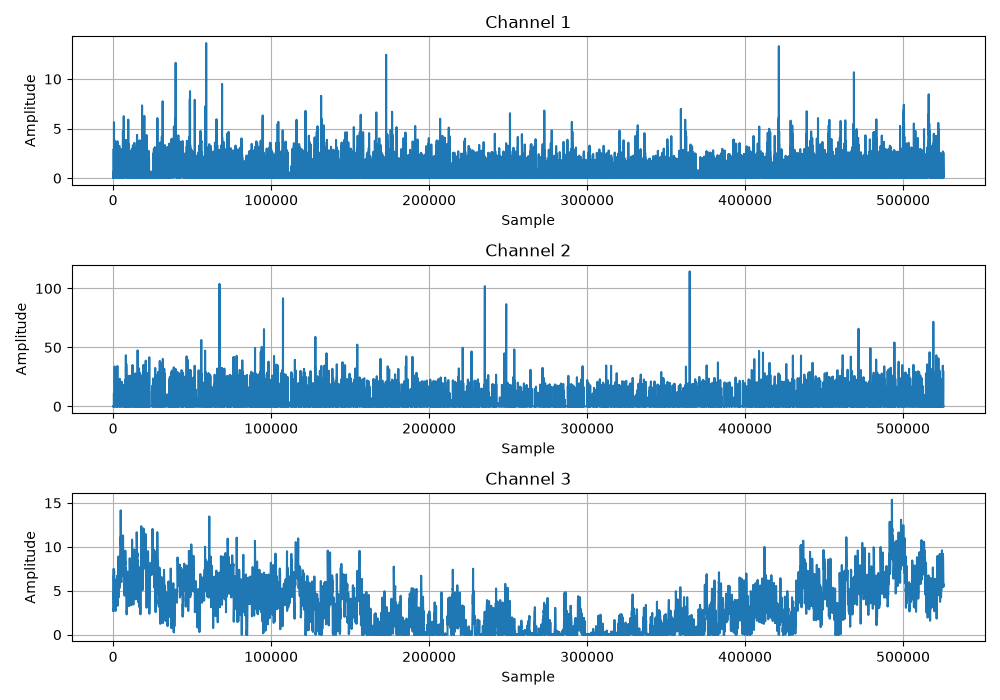

In [73]:
import matplotlib.pyplot as plt

# Tensor shape: [4, 3, 525600]
batch = raw[5]  # Shape: [3, 525600]

fig, axes = plt.subplots(3, 1, figsize=(10, 7))

for i in range(3):
    axes[i].plot(batch[i].detach().cpu().numpy())
    axes[i].set_title(f"Channel {i + 1}")
    axes[i].set_xlabel("Sample")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

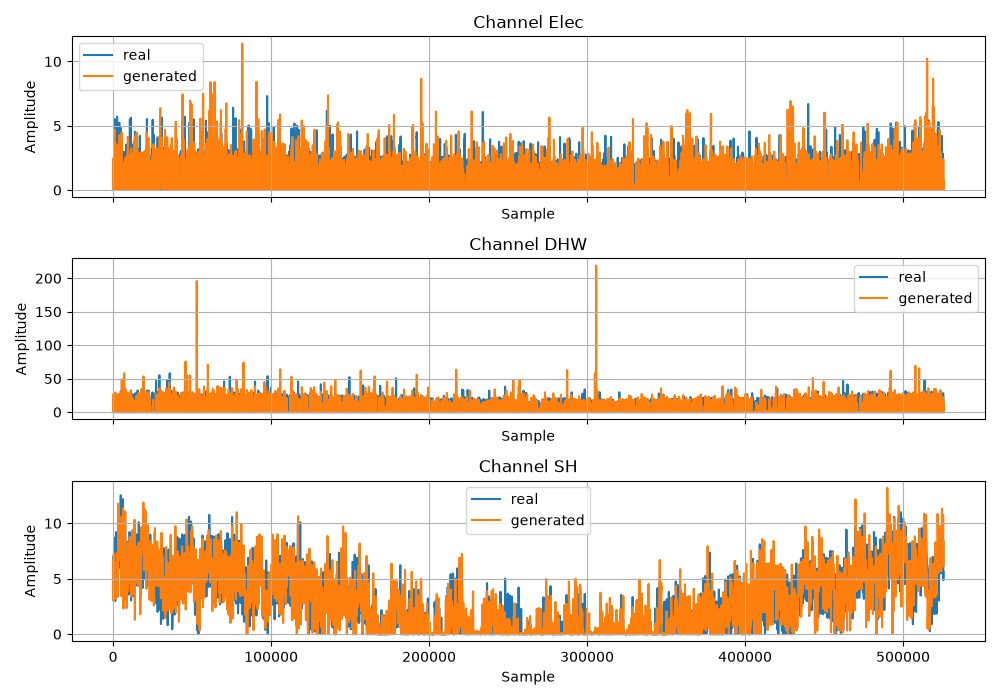

In [74]:
import matplotlib.pyplot as plt


batch = raw[4]
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

axes[0].plot(real_year_data["Electricity Load"].reset_index(drop=True), zorder=0, label="real")
axes[0].plot(batch[0].detach().cpu().numpy(), zorder=1, label="generated")
axes[0].set_title(f"Channel Elec")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)
axes[0].legend()
axes[1].plot(real_year_data["Hot Water Load"].reset_index(drop=True), label="real",zorder=0)
axes[1].plot(batch[1].detach().cpu().numpy(), label="generated", zorder=1)
axes[1].set_title(f"Channel DHW")
axes[1].set_xlabel("Sample")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)
axes[1].legend()
axes[2].plot(real_year_data["Heating Load"].reset_index(drop=True), label="real",zorder=0)
axes[2].plot(batch[2].detach().cpu().numpy(), label="generated", zorder=1)
axes[2].set_title(f"Channel SH")
axes[2].set_xlabel("Sample")
axes[2].set_ylabel("Amplitude")
axes[2].grid(True)
axes[2].legend()
plt.tight_layout()
plt.show()

In [84]:
path

WindowsPath('../DataSplit/Data/val/run_011684.h5')

In [85]:
data_test = pd.read_hdf(path, key="timeseries")

In [86]:
path

WindowsPath('../DataSplit/Data/val/run_011684.h5')

In [87]:
df =real_year_data[["Electricity Load","Hot Water Load", "Heating Load"]]

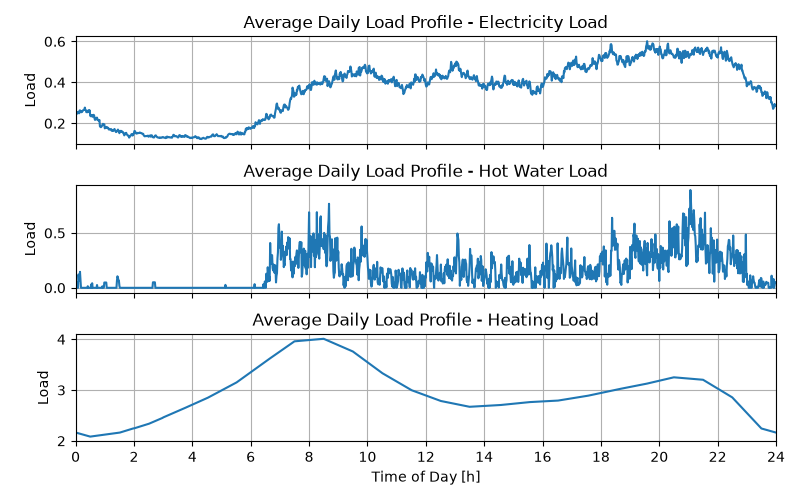

In [88]:
# Ensure datetime index
df.index = pd.to_datetime(df.index)

# Group by hour and minute of day
minute_of_day = df.index.hour * 60 + df.index.minute

avg_daily_profile = df.groupby(minute_of_day).mean()

# Plot
fig, axes = plt.subplots(3, 1, figsize=(8, 5), sharex=True)

for ax, column in zip(axes, df.columns):
    ax.plot(avg_daily_profile.index / 60, avg_daily_profile[column])
    ax.set_title(f"Average Daily Load Profile - {column}")
    ax.set_ylabel("Load")
    ax.grid(True)

axes[-1].set_xlabel("Time of Day [h]")
axes[-1].set_xticks(np.arange(0, 25, 2))

plt.xlim(0, 24)
plt.tight_layout()
plt.show()

In [89]:
# Original shape: [4, 3, 525600]
batch = raw[3]  # [3, 525600]

# [4, 3, 525600] -> [4, 3, 365, 1440]
daily_profiles = raw.reshape(8, 3, 365, 1440)

# Average over batches and days
avg_daily_profile = daily_profiles.mean(dim=(0, 2))

print(avg_daily_profile.shape)
# torch.Size([3, 1440])

print(avg_daily_profile.shape)
# torch.Size([3, 1440])

torch.Size([3, 1440])
torch.Size([3, 1440])


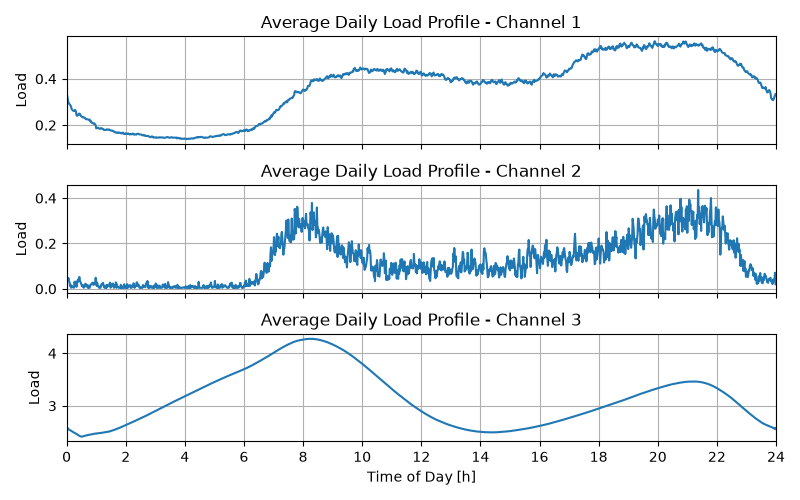

In [90]:
import matplotlib.pyplot as plt
import numpy as np

# Convert minutes to hours
hours = np.arange(1440) / 60

fig, axes = plt.subplots(3, 1, figsize=(8, 5), sharex=True)

for i in range(3):
    axes[i].plot(
        hours,
        avg_daily_profile[i].detach().cpu().numpy()
    )
    axes[i].set_title(f"Average Daily Load Profile - Channel {i+1}")
    axes[i].set_ylabel("Load")
    axes[i].grid(True)

axes[-1].set_xlabel("Time of Day [h]")
axes[-1].set_xticks(np.arange(0, 25, 2))

plt.xlim(0, 24)
plt.tight_layout()
plt.show()

In [180]:
raw_cond[:,3,:].shape

torch.Size([64, 525600])

In [94]:
raw_cond[:,1,:].shape

torch.Size([8, 525600])

In [106]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Select first batch
batch = raw[0]  # [3, 525600]

# Select corresponding offday information
offday = raw_cond[:,1,:]  # [525600]

# Shape: [4, 3, 365, 1440]
daily_profiles = raw.reshape(8, 3, 365, 1440)

# Shape: [4, 365, 1440]
offday_daily = offday.reshape(8, 365, 1440)

# Mask for each day in each batch
offday_mask = offday_daily[:, :, 0] == 1

# Rearrange to [4, 365, 3, 1440]
daily_profiles = daily_profiles.permute(0, 2, 1, 3)

# Select all weekday/offday profiles across batches
avg_weekday = daily_profiles[~offday_mask].mean(dim=0)
avg_offday = daily_profiles[offday_mask].mean(dim=0)

print(avg_weekday.shape)  # [3, 1440]
print(avg_offday.shape)   # [3, 1440]

torch.Size([3, 1440])
torch.Size([3, 1440])


In [104]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Select first batch
batch = raw[5]  # [3, 525600]

# Select corresponding offday information
offday = raw_cond[5][1]  # [525600]

# Reshape into daily profiles
daily_profiles = batch.reshape(3, 365, 1440)
offday_daily = offday.reshape(365, 1440)

# Create masks (one indicator per day)
offday_mask = offday_daily[:, 0] == 1
weekday_mask = ~offday_mask

# Calculate average daily profiles
avg_weekday = daily_profiles[:, weekday_mask, :].mean(dim=1)
avg_offday = daily_profiles[:, offday_mask, :].mean(dim=1)

print(avg_weekday.shape)  # [3, 1440]
print(avg_offday.shape)   # [3, 1440]

torch.Size([3, 1440])
torch.Size([3, 1440])


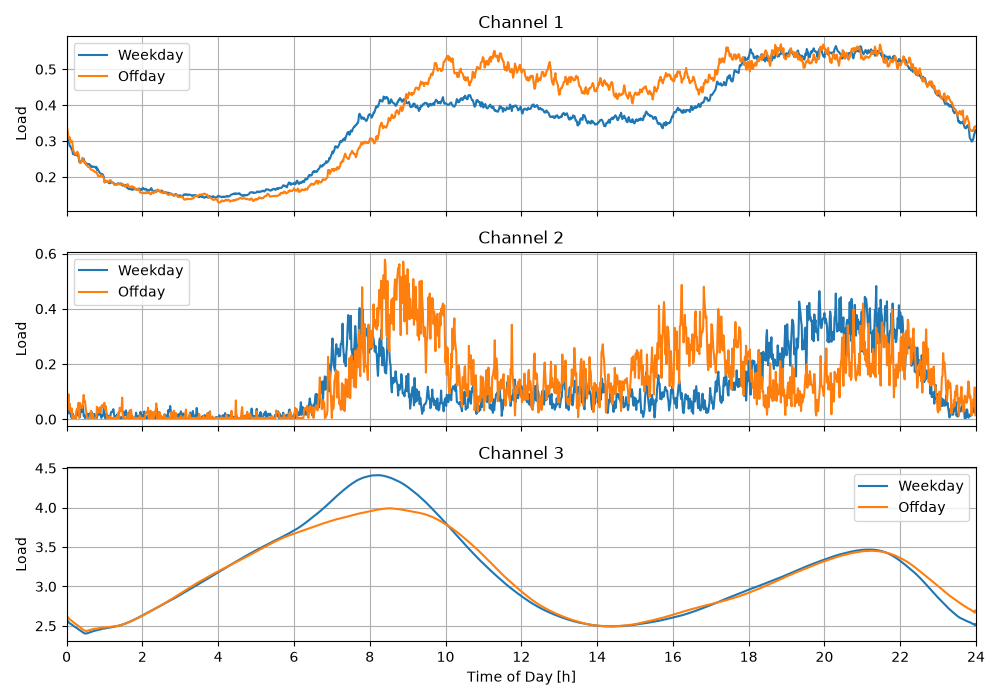

In [107]:
hours = np.arange(1440) / 60

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

for i in range(3):
    axes[i].plot(
        hours,
        avg_weekday[i].detach().cpu().numpy(),
        label="Weekday"
    )

    axes[i].plot(
        hours,
        avg_offday[i].detach().cpu().numpy(),
        label="Offday"
    )

    axes[i].set_title(f"Channel {i+1}")
    axes[i].set_ylabel("Load")
    axes[i].legend()
    axes[i].grid(True)

axes[-1].set_xlabel("Time of Day [h]")
axes[-1].set_xticks(np.arange(0, 25, 2))

plt.xlim(0, 24)
plt.tight_layout()
plt.show()

In [98]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Copy dataframe
df = real_year_data[["Electricity Load","Hot Water Load", "Heating Load", "Off Day"]]

# Create minute-of-day index (0 to 1439)
df["minute_of_day"] = np.arange(len(df)) % 1440

# Select load channels
channels = ["Electricity Load","Hot Water Load", "Heating Load"]

# Calculate average weekday profile
avg_weekday = (
    df[df["Off Day"] == 0]
    .groupby("minute_of_day")[channels]
    .mean()
)

# Calculate average offday profile
avg_offday = (
    df[df["Off Day"] == 1]
    .groupby("minute_of_day")[channels]
    .mean()
)

print(avg_weekday.shape)  # (1440, 3)
print(avg_offday.shape)   # (1440, 3)

(1440, 3)
(1440, 3)


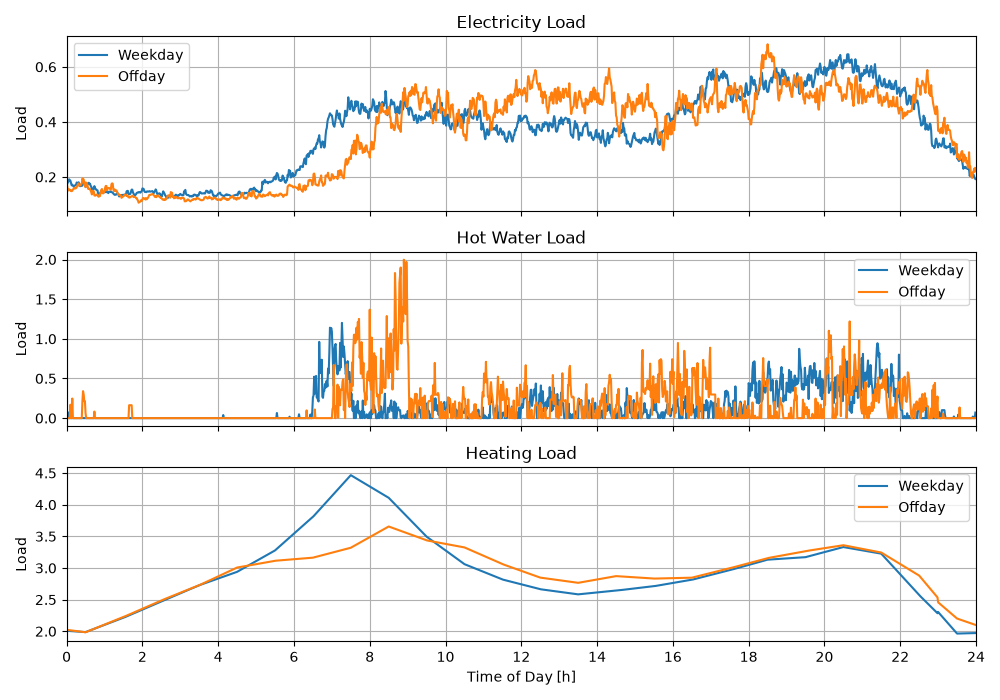

In [99]:
hours = np.arange(1440) / 60

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

for i, channel in enumerate(channels):
    axes[i].plot(
        hours,
        avg_weekday[channel],
        label="Weekday"
    )

    axes[i].plot(
        hours,
        avg_offday[channel],
        label="Offday"
    )

    axes[i].set_title(channel)
    axes[i].set_ylabel("Load")
    axes[i].legend()
    axes[i].grid(True)

axes[-1].set_xlabel("Time of Day [h]")
axes[-1].set_xticks(np.arange(0, 25, 2))

plt.xlim(0, 24)
plt.tight_layout()
plt.show()

In [79]:
real_year_data

,T,Occupancy Home Active,Occupancy Home Not Active,Electricity Load,Hot Water Load,Heating Load,Off Day
2023-01-01 00:00:00+01:00,-2.2,4.0,13.0,0.932886,0.0,26.767090,1
2023-01-01 00:01:00+01:00,-2.2,4.0,13.0,0.932886,0.0,26.767090,1
2023-01-01 00:02:00+01:00,-2.2,4.0,13.0,1.016240,0.0,26.767090,1
2023-01-01 00:03:00+01:00,-2.2,4.0,13.0,1.095027,0.0,26.767090,1
2023-01-01 00:04:00+01:00,-2.2,4.0,13.0,1.187516,0.0,26.767090,1
...,...,...,...,...,...,...,...
2023-12-31 23:55:00+01:00,0.4,4.0,18.0,6.100317,0.0,14.211451,1
2023-12-31 23:56:00+01:00,0.4,4.0,18.0,6.093550,0.0,14.211451,1
2023-12-31 23:57:00+01:00,0.4,4.0,18.0,6.035551,0.0,14.211451,1
2023-12-31 23:58:00+01:00,0.4,4.0,18.0,5.984375,0.0,14.211451,1


In [287]:
out[0]

torch.Size([525600])

In [ ]:
raw = invert_scaler(out.cpu(), target_scaler) * ds.target_norm[run_id]   # (B, 2, T) in real units

In [148]:
val_df[val_df["buildingType"]=="TH"].groupby("n_persons_sum").size()

n_persons_sum
1    108
2    201
3     75
4     45
5     21
dtype: int64

In [33]:
f1 = 8
f2 =9
example = next(iter(val_dataloader))
trgt = example["target"][f1:f2].repeat(32, 1, 1).to(device)
static_cat = example["static_cat"][f1:f2].repeat(32, 1).to(device)
static_cont = example["static_cont"][f1:f2].repeat(32, 1).to(device)
static_bool = example["static_bool"][f1:f2].repeat(32, 1).to(device)
dyn = example["condition"][f1:f2].repeat(32, 1, 1).to(device)
target_norm = example["target_norm"][f1:f2].repeat(32, 1, 1).to(device)
condition_norm = example["condition_norm"][f1:f2].repeat(32, 1, 1).to(device)
decode_static(preprocessor, static_cat[:1], static_cont[:1], static_bool[:1]) #todo check how appliances are encoded

,buildingType,buildingAgeBin,year_type,climateRegion,n_persons_sum,a_ref,n_apartments,apl_ANSWER_MACHINE,apl_CD_PLAYER,apl_CHEST_FREEZER,...,apl_RECEIVER,apl_TUMBLE_DRYER,apl_TV1,apl_TV2,apl_TV3,apl_UPRIGHT_FREEZER,apl_VACUUM,apl_VCR_DVD,apl_WASHER_DRYER,apl_WASHING_MACHINE
0,MFH,DE.04,average,1,14.0,718.672974,8.0,1.0,0.75,0.125,...,1.0,0.25,1.0,0.25,0.125,0.25,0.75,0.875,0.0,0.625


In [32]:
def decode_static(pp, cat, cont, boolean):
    cat_df = pd.DataFrame(pp.cat_encoder.inverse_transform((cat.cpu().numpy() - 1)),
                          columns=pp.static_cat_cols)
    cont_df = pd.DataFrame(pp.cont_scaler.inverse_transform(cont.cpu().numpy()),
                           columns=pp.static_cont_cols)
    bool_df = pd.DataFrame(boolean.cpu().numpy() > 0.5, columns=pp.static_bool_cols)
    return pd.concat([cat_df, cont_df, bool_df], axis=1)


In [111]:
def decode_dynamic(dyn, condition_scaler, condition_norm, cols):
    """dyn: (B, C, T) scaled condition -> DataFrame (T x C) in physical units"""
    phys = invert_scaler(dyn.clone(), condition_scaler) * condition_norm   # (B, C, T)
    return pd.DataFrame(phys[0].cpu().numpy().T, columns=cols)



RuntimeError: The size of tensor a (7) must match the size of tensor b (3) at non-singleton dimension 1

In [107]:
#cond = build_condition(preprocessor, train_df,{"buildingType": "SFH", "sum_n_persons": 3, "future": False}, batch_size=32, device=device)

In [35]:
samples = sample1d(
    ema.ema_model,
    sequence_length=1440,
    batch_size=32,
    channels=3,
    schedule=schedule,
    static_cat=static_cat,
    static_cont=static_cont,
    static_bool=static_bool,
    dyn=dyn,
    clip_range=(X0_MIN1, X0_MAX1)
)

sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

In [40]:
samples.shape

torch.Size([32, 3, 1440])

In [77]:
COLD = ["FRIDGE", "FRIDGE_FREEZER", "UPRIGHT_FREEZER", "CHEST_FREEZER"]
cold_cols = [f"app_{a}" for a in COLD]
assert all(c in preprocessor.static_cont_cols for c in cold_cols)

def set_shares(static_cont, preprocessor, **shares):
    sc = static_cont.clone()
    cols = list(preprocessor.static_cont_cols)
    for col, val in shares.items():
        i = cols.index(col)
        sc[:, i] = (val - preprocessor.cont_scaler.mean_[i]) / preprocessor.cont_scaler.scale_[i]
    return sc

def sample_with(sc, seed=0):
    dev = next(ema.ema_model.parameters()).device
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    out = sample1d(
        ema.ema_model, sequence_length=1440, batch_size=32, channels=2,
        static_cat=static_cat.to(dev), static_cont=sc.to(dev),
        static_bool=static_bool.to(dev), dyn=dyn.to(dev),
    )
    return out[-1]
no_cold  = set_shares(static_cont, preprocessor, **{c: 0.0 for c in cold_cols})
all_cold = set_shares(static_cont, preprocessor, **{c: 1.0 for c in cold_cols})

x_base = sample_with(static_cont)
x_off  = sample_with(no_cold)
x_on   = sample_with(all_cold)
x_on_b = sample_with(all_cold, seed=1)   # noise-only control

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

In [101]:
def cold_scenario(on=(), off_value=0.0, on_value=1.0):
    vals = {c: off_value for c in cold_cols}
    vals.update({f"app_{a}": on_value for a in on})
    return set_shares(static_cont, preprocessor, **vals)

sc_1 = cold_scenario(on=["FRIDGE_FREEZER"])                 # 1 appliance (most common single case)
sc_2 = cold_scenario(on=["FRIDGE", "UPRIGHT_FREEZER"])      # 2 appliances: fridge + separate freezer
sc_2b = cold_scenario(on=["FRIDGE_FREEZER", "CHEST_FREEZER"])  # 2 appliances: fridge-freezer + extra freezer

x_1  = sample_with(sc_1)
x_2  = sample_with(sc_2)
x_2b = sample_with(sc_2b)

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

In [78]:
i =3
final_samples = torch.as_tensor(x_on).float().cpu()
dyn = dyn.cpu()
trgt = trgt.cpu()
condition_norm = condition_norm.cpu()
target_norm = target_norm.cpu()

occ  = (invert_scaler(dyn, condition_scaler) * condition_norm)[i]
gen  = (invert_scaler(final_samples, target_scaler)*target_norm)[i]
real = (invert_scaler(trgt, target_scaler)*target_norm)[i]



occ_activ, occ_not_active = occ[0], occ[1]
elec_gen, dhw_gen = gen[0], gen[1]
elec_real, dhw_real = real[0], real[1]


fig, ax = plt.subplots(3,1, figsize=(10,7))

ax[0].plot(elec_gen, label="generated")
ax[0].plot(elec_real, label="real")
ax[0].set_ylabel("elec in kW")
ax[0].set_xlabel("1min timesteps")
ax[0].legend()

ax[1].plot(dhw_gen, label="generated")
ax[1].plot(dhw_real, label="real")
ax[1].set_ylabel("dhw in kW")
ax[1].set_xlabel("1min timesteps")

ax[2].plot(occ_activ, label="occ active", color="r")
ax[2].plot(occ_not_active, label="occ not active", color="g")
ax[2].set_ylabel("occupants")
ax[2].set_xlabel("1min timesteps")
ax[2].legend()

plt.show()
#todo conntext as single value in static embedding
#todo check quality of unnormalized version

NameError: name 'x_on' is not defined

In [89]:
x_base = sample_with(static_cont)
x_off  = sample_with(no_cold)
x_on   = sample_with(all_cold)
x_on_b = sample_with(all_cold, seed=1)
print("on vs off:", np.abs(x_on - x_off).mean())
print("on vs on(seed 1):", np.abs(x_on - x_on_b).mean())

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [88]:
m = ema.ema_model
a = m.cond_embedder(static_cat[:1], static_cont[:1], static_bool[:1])
b = m.cond_embedder(static_cat[:1], all_cold[:1], static_bool[:1])
print((a - b).norm(), a.norm())

tensor(3.8611, device='cuda:0') tensor(4.5011, device='cuda:0')


In [79]:
dyn[0]

tensor([[ 0.4584,  0.4584,  0.4584,  ..., -0.2091, -0.2091, -0.2091],
        [ 1.1330,  1.1330,  1.1330,  ...,  1.9006,  1.9006,  1.9006],
        [ 0.2961,  0.2949,  0.2937,  ..., -0.4996, -0.5006, -0.5016],
        ...,
        [-0.1944, -0.1944, -0.1944,  ...,  0.0000,  0.0000,  0.0000],
        [-0.1493, -0.1575, -0.1658,  ...,  0.0000,  0.0000,  0.0000],
        [ 1.0000,  1.0000,  1.0000,  ...,  0.0000,  0.0000,  0.0000]])

In [73]:
occ

tensor([[0., 0., 0.,  ..., 1., 1., 1.],
        [2., 2., 2.,  ..., 0., 0., 0.],
        [1., 1., 1.,  ..., 1., 1., 1.]])

In [42]:
samples.type

<function Tensor.type>

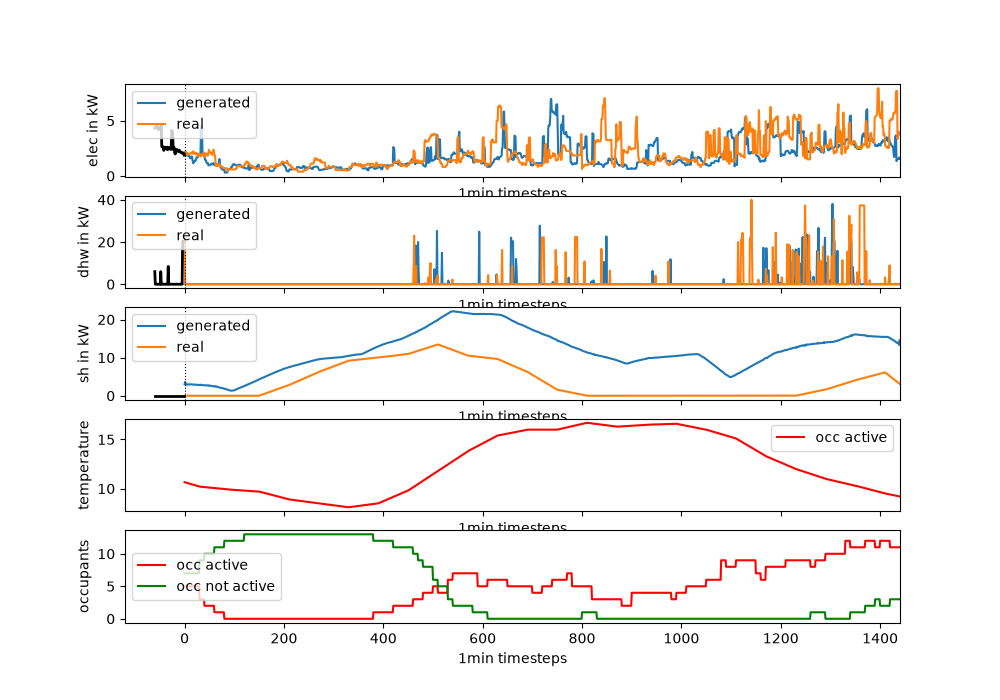

In [36]:
i =0
final_samples = torch.as_tensor(samples).float().cpu()
trgt1 = trgt.cpu()
condition_norm1 = condition_norm.cpu()
target_norm1 = target_norm.cpu()

n_d, n_t = len(DYNAMIC_COND_COLS), len(TARGET_COLS)
dyn_c = dyn.cpu()

occ = (invert_scaler(dyn_c[:, :n_d], condition_scaler) * condition_norm1)[i]
gen  = (invert_scaler(final_samples, target_scaler)*target_norm1)[i]
real = (invert_scaler(trgt1, target_scaler)*target_norm1)[i]



occ_activ, occ_not_active, temp = occ[0], occ[1], occ[2]
elec_gen, dhw_gen, sh_gen = gen[0], gen[1], gen[2]
elec_real, dhw_real, sh_real = real[0], real[1], real[2]

# occ_activ, occ_not_active = occ[0], occ[1]
# elec_gen= gen[0]
# elec_real = real[0]

fig, ax = plt.subplots(5,1, figsize=(10,7), sharex=True)

ax[0].plot(elec_gen, label="generated")
ax[0].plot(elec_real, label="real")
ax[0].set_ylabel("elec in kW")
ax[0].set_xlabel("1min timesteps")
ax[0].legend()

ax[1].plot(dhw_gen, label="generated")
ax[1].plot(dhw_real, label="real")
ax[1].set_ylabel("dhw in kW")
ax[1].set_xlabel("1min timesteps")
ax[1].legend()

ax[2].plot(sh_gen, label="generated")
ax[2].plot(sh_real, label="real")
ax[2].set_ylabel("sh in kW")
ax[2].set_xlabel("1min timesteps")
ax[2].legend()

ax[3].plot(temp, label="occ active", color="r")
ax[3].set_ylabel("temperature")
ax[3].set_xlabel("1min timesteps")
ax[3].legend()

ax[4].plot(occ_activ, label="occ active", color="r")
ax[4].plot(occ_not_active, label="occ not active", color="g")
ax[4].set_ylabel("occupants")
ax[4].set_xlabel("1min timesteps")
ax[4].legend()
offday = occ[3]                                   # 0/1 after minmax inversion
mask = dyn_c[i, -1] > 0.5
o = n_d + N_SEASON
ctx = (invert_scaler(dyn_c[:, o:o + n_t], target_scaler) * target_norm1)[i]   # (n_t, L)
CONTEXT_REVERSE = True
K_eff = int(mask.sum())
for k, a in enumerate(ax[:3]):
    ctx_k = ctx[k, :K_eff]
    if CONTEXT_REVERSE:
        ctx_k = ctx_k.flip(-1)                      # slot 0 holds the newest minute, so flip to oldest to newest
    a.plot(np.arange(-K_eff, 0), ctx_k, color="k", lw=2, label="end of previous day (context)")
    a.axvline(0, color="k", ls=":", lw=0.8)
ax[0].set_xlim(-2 * K_eff, 1440)
plt.show()
#todo conntext as single value in static embedding
#todo check quality of unnormalized version

## DPM Sampling

In [64]:
from diffusers import DPMSolverMultistepScheduler

scheduler = DPMSolverMultistepScheduler(
    num_train_timesteps=timesteps,        # 1000
    trained_betas=betas.numpy(),          # your sigmoid betas
    prediction_type="epsilon",
    algorithm_type="dpmsolver++",         # or "sde-dpmsolver++" for stochastic sampling
    solver_order=2,                       # 2 is the safe default for conditional models
    timestep_spacing="trailing",          # more stable at low step counts
    lower_order_final=True,
)

@torch.inference_mode()
def sample_dpm(model, shape, static_cat, static_cont, static_bool, dyn=None,
               num_steps=20, clip_denoised=True, tqdm_disabled=True):
    device = next(model.parameters()).device
    scheduler.set_timesteps(num_steps, device=device)
    ac = alphas_cumprod.to(device)
    lo, hi = X0_MIN.to(device), X0_MAX.to(device)

    x = torch.randn(shape, device=device)
    for t in tqdm(scheduler.timesteps, desc="DPM-Solver", disable=tqdm_disabled):
        tb = torch.full((shape[0],), int(t), device=device, dtype=torch.long)
        eps = model(x, tb, static_cat, static_cont, static_bool, dyn)

        if clip_denoised:  # same x0 clamp as p_sample, re-expressed in eps space
            a = ac[t]
            x0 = (x - (1 - a).sqrt() * eps) / a.sqrt()
            x0 = torch.clamp(x0, lo, hi)
            eps = (x - a.sqrt() * x0) / (1 - a).sqrt()

        x = scheduler.step(eps, t, x).prev_sample
    return x.cpu()

In [110]:
samples_dpm = sample_dpm(
    ema.ema_model,
    shape=(32, 3, 1440),
    static_cat=static_cat,
    static_cont=static_cont,
    static_bool=static_bool,
    dyn=dyn,
    num_steps=50,
)

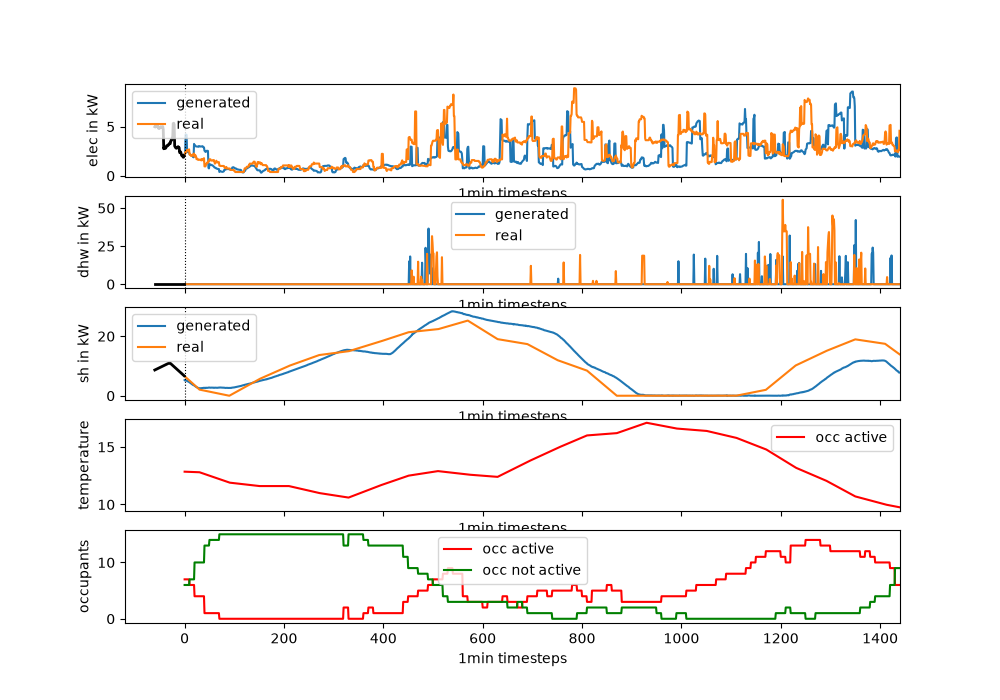

In [259]:
i =6
final_samples = torch.as_tensor(samples_dpm).float().cpu()
trgt1 = trgt.cpu()
condition_norm1 = condition_norm.cpu()
target_norm1 = target_norm.cpu()

n_d, n_t = len(DYNAMIC_COND_COLS), len(TARGET_COLS)
dyn_c = dyn.cpu()

occ = (invert_scaler(dyn_c[:, :n_d], condition_scaler) * condition_norm1)[i]
gen  = (invert_scaler(final_samples, target_scaler)*target_norm1)[i]
real = (invert_scaler(trgt1, target_scaler)*target_norm1)[i]


# occ_activ, occ_not_active = occ[0], occ[1]
# elec_gen= gen[0]
# elec_real = real[0]
occ_activ, occ_not_active, temp = occ[0], occ[1], occ[2]
elec_gen, dhw_gen, sh_gen = gen[0], gen[1], gen[2]
elec_real, dhw_real, sh_real = real[0], real[1], real[2]



fig, ax = plt.subplots(5,1, figsize=(10,7), sharex=True)

ax[0].plot(elec_gen, label="generated")
ax[0].plot(elec_real, label="real")
ax[0].set_ylabel("elec in kW")
ax[0].set_xlabel("1min timesteps")
ax[0].legend()

ax[1].plot(dhw_gen, label="generated")
ax[1].plot(dhw_real, label="real")
ax[1].set_ylabel("dhw in kW")
ax[1].set_xlabel("1min timesteps")
ax[1].legend()

ax[2].plot(sh_gen, label="generated")
ax[2].plot(sh_real, label="real")
ax[2].set_ylabel("sh in kW")
ax[2].set_xlabel("1min timesteps")
ax[2].legend()

ax[3].plot(temp, label="occ active", color="r")
ax[3].set_ylabel("temperature")
ax[3].set_xlabel("1min timesteps")
ax[3].legend()

ax[4].plot(occ_activ, label="occ active", color="r")
ax[4].plot(occ_not_active, label="occ not active", color="g")
ax[4].set_ylabel("occupants")
ax[4].set_xlabel("1min timesteps")
ax[4].legend()

offday = occ[3]                                   # 0/1 after minmax inversion
mask = dyn_c[i, -1] > 0.5
o = n_d + N_SEASON
ctx = (invert_scaler(dyn_c[:, o:o + n_t], target_scaler) * target_norm1)[i]   # (n_t, L)
CONTEXT_REVERSE = True
K_eff = int(mask.sum())
for k, a in enumerate(ax[:3]):
    ctx_k = ctx[k, :K_eff]
    if CONTEXT_REVERSE:
        ctx_k = ctx_k.flip(-1)                      # slot 0 holds the newest minute, so flip to oldest to newest
    a.plot(np.arange(-K_eff, 0), ctx_k, color="k", lw=2, label="end of previous day (context)")
    a.axvline(0, color="k", ls=":", lw=0.8)
ax[0].set_xlim(-2 * K_eff, 1440)
plt.show()
#todo conntext as single value in static embedding
#todo check quality of unnormalized version

In [228]:
def start_level(dyn_variant):
    out = sample_final(ema.ema_model, shape, static_cat, static_cont, static_bool, dyn_variant)
    return invert_scaler(out, target_scaler)[:, 0, :10].mean()       # first 10 min, elec, scaled->physical as needed

d_real = dyn.clone()
d_none = dyn.clone(); d_none[:, o:] = 0                              # context + mask off
d_high = dyn.clone(); d_high[:, o:o + n_t, :K_eff] += 3.0            # artificially high tail

In [ ]:
#torch.save(ema.ema_model.state_dict(), "model_DHW_ema.pth")

In [ ]:
cond = build_condition(preprocessor, train_df,{"buildingType": "SFH", "sum_n_persons": 4, "future": True}, batch_size=32, device=device)

## Validation - t-SNE

In [136]:
res = draw_sampling_windows(val_df_exist,strat_cols,1, 1,1440)

In [137]:
res

,run_id,start_hour,day,building_id,buildingType,buildingAgeBin,year
0,run_000198,17280,12,49,AB,DE.02,2023
1,run_000198,60480,42,49,AB,DE.02,2023
2,run_000198,126720,88,49,AB,DE.02,2023
3,run_000198,131040,91,49,AB,DE.02,2023
4,run_000198,187200,130,49,AB,DE.02,2023
...,...,...,...,...,...,...,...
451,run_015716,339840,236,3929,TH,DE.12,2018
452,run_015716,351360,244,3929,TH,DE.12,2018
453,run_015716,430560,299,3929,TH,DE.12,2018
454,run_015716,442080,307,3929,TH,DE.12,2018


In [138]:
sample_dataset = SampleWindowDataset(
    index=res,
    split_files=val_files,
    gen_cols=TARGET_COLS,
    cond_cols=DYNAMIC_COND_COLS,
    window_length=WINDOW_LENGTH,
    stride=STRIDE,
    target_scaler=target_scaler,
    condition_scaler=condition_scaler,
    static_by_run_id=val_static,
    resolution=RESOLUTION,
    aggregation=TS_AGG,
    target_norm=build_norm_factors(val_df, TARGET_COLS, NORM_BY_COL),
    condition_norm=build_norm_factors(val_df, DYNAMIC_COND_COLS, NORM_BY_COL)
)

In [139]:
torch.manual_seed(0)
ema.ema_model.eval()

sample_dataloader = DataLoader(
    sample_dataset,
    batch_size=BATCH_SIZE,
    num_workers=0,
)

In [140]:

real, gen, rows = [],[],[]

for batch in tqdm(sample_dataloader, desc="batches"):
    x_real = batch["target"]
    B,C,L = x_real.shape
    x_gen = sample_final(
        ema.ema_model,
        (B,C,L),
        static_cat=batch["static_cat"].to(device),
        static_cont=batch["static_cont"].to(device),
        static_bool=batch["static_bool"].to(device),
        dyn=batch["condition"].to(device),
    )

    real.append(x_real.numpy())
    gen.append(x_gen.numpy())
    rows.append(batch["row"].numpy())

order = np.argsort(np.concatenate(rows))
real = np.concatenate(real)[order]
gen = np.concatenate(gen)[order]
assert len(real) == len(sample_dataset.index)
np.savez("tsne_samples_val.npz", real=real, gen=gen)
sample_dataset.index.to_parquet("tsne_samples_val_index.parquet")


batches:   0%|          | 0/15 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

...

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

sampling loop time step:   0%|          | 0/1000 [00:00<?, ?it/s]

In [141]:
print(BATCH_SIZE, len(sample_dataset), len(sample_dataloader))

32 456 15


In [142]:
n_yielded = sum(b["target"].shape[0] for b in sample_dataloader)
print(n_yielded, len(sample_dataset.index))

456 456


In [73]:
sample_dataset.index

,run_id,start_hour,day,building_id,buildingType,buildingAgeBin,year
0,run_000198,17280,12,49,AB,DE.02,2023
1,run_000198,60480,42,49,AB,DE.02,2023
2,run_000198,126720,88,49,AB,DE.02,2023
3,run_000198,131040,91,49,AB,DE.02,2023
4,run_000198,187200,130,49,AB,DE.02,2023
...,...,...,...,...,...,...,...
451,run_015716,339840,236,3929,TH,DE.12,2018
452,run_015716,351360,244,3929,TH,DE.12,2018
453,run_015716,430560,299,3929,TH,DE.12,2018
454,run_015716,442080,307,3929,TH,DE.12,2018


In [121]:
# def load_windows(index, split_files=val_files, batch_size=BATCH_SIZE):
#     ds = SampleWindowDataset(
#         index=index,
#         split_files=split_files,
#         gen_cols=TARGET_COLS,
#         cond_cols=DYNAMIC_COND_COLS,
#         window_length=WINDOW_LENGTH,
#         stride=STRIDE,
#         target_scaler=target_scaler,
#         condition_scaler=condition_scaler,
#         static_by_run_id=val_static,
#         resolution=RESOLUTION,
#         aggregation=TS_AGG,
#         target_norm=build_norm_factors(val_df, TARGET_COLS, NORM_BY_COL),
#         condition_norm=build_norm_factors(val_df, DYNAMIC_COND_COLS, NORM_BY_COL),
#     )
#     dl = DataLoader(ds, batch_size=batch_size, num_workers=0)
#
#     windows, rows = [], []
#     for batch in tqdm(dl):
#         windows.append(batch["target"].numpy())
#         rows.append(batch["row"].numpy())
#
#     windows, rows = np.concatenate(windows), np.concatenate(rows)
#     assert len(windows) == len(ds.index)
#     return windows[np.argsort(rows)], ds.index        # also return the filtered index

In [182]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

d = np.load("tsne_samples_val.npz")
real, gen = d["real"], d["gen"]                       # (N, C, 1440), scaled
meta = pd.read_parquet("tsne_samples_val_index.parquet")
N = len(real)
assert len(meta) == N == len(gen)

In [184]:
# 1) flatten channels x time, stack real + generated
X = np.concatenate([real, gen]).reshape(2 * N, -1).astype(np.float32)
label = np.array(["real"] * N + ["generated"] * N)
# todo check good parameters for PCA
# 2) PCA (fit on the stack, so both sets share one space)
pca = PCA(n_components=912, svd_solver="randomized", random_state=0)
Z = pca.fit_transform(X)
print("explained variance (50 comps):", pca.explained_variance_ratio_.sum().round(3))

# 3) t-SNE
emb = TSNE(n_components=2, perplexity=50, init="pca", learning_rate="auto",
           random_state=0, n_jobs=-1).fit_transform(Z)

np.save("tsne_emb_val.npy", emb)

explained variance (50 comps): 1.0


In [152]:
def pca_and_tsne(a,b,meta_a,meta_b):
    X = np.concatenate([a, b]).reshape(2 * N, -1).astype(np.float32)


In [153]:
np.concatenate([real, gen]).shape

(912, 2, 1440)

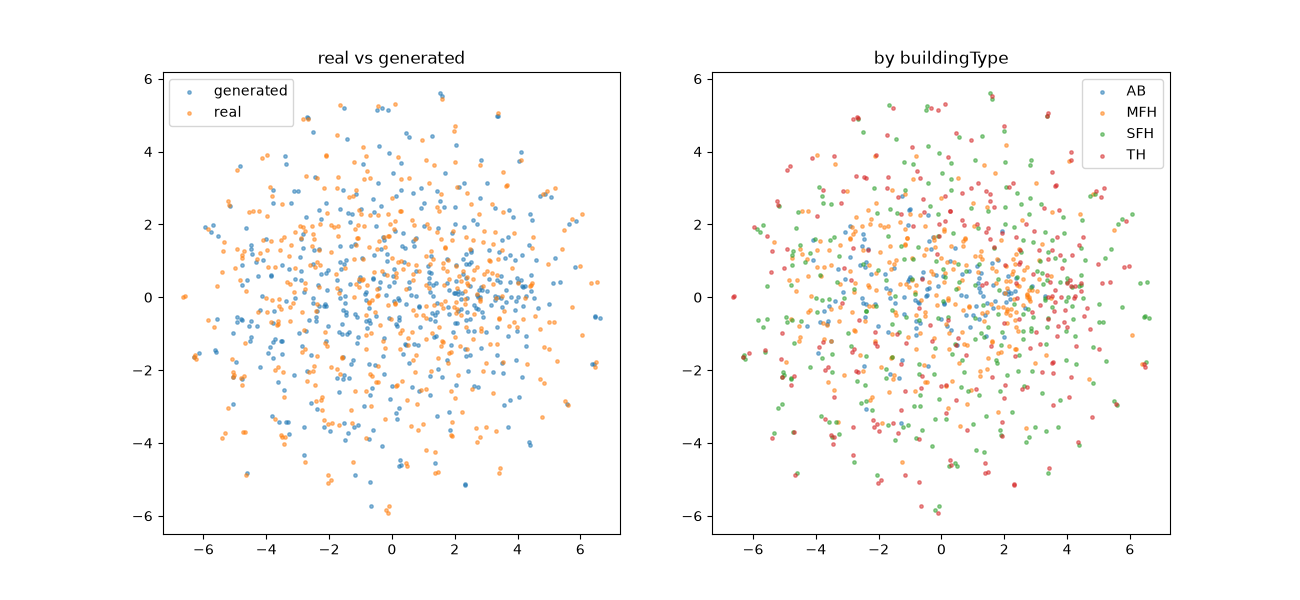

In [185]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6))

# real vs generated
for name, c in [("generated", "tab:blue"),("real", "tab:orange")]:
    m = label == name
    ax[0].scatter(*emb[m].T, s=6, alpha=0.5, c=c, label=name)
ax[0].legend(); ax[0].set_title("real vs generated")

# colour by metadata (real and generated share the same condition, so tile it twice)
cat = pd.concat([meta["buildingType"]] * 2).to_numpy()
for v in np.unique(cat):
    m = cat == v
    ax[1].scatter(*emb[m].T, s=6, alpha=0.5, label=v)
ax[1].legend(); ax[1].set_title("by buildingType")
plt.show()

In [186]:
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

# classifier two-sample test: 0.5 = indistinguishable, 1.0 = perfectly separable
y = (label == "generated").astype(int)
auc = cross_val_score(LogisticRegression(max_iter=1000), Z, y, cv=5, scoring="roc_auc").mean()

# kNN: fraction of each window's 10 nearest neighbours that are generated (ideal ~0.5)
_, nn = NearestNeighbors(n_neighbors=11).fit(Z).kneighbors(Z)
frac_gen = y[nn[:, 1:]].mean(axis=1)
print(f"AUC {auc:.3f}, kNN generated-share real={frac_gen[:N].mean():.2f}, gen={frac_gen[N:].mean():.2f}")

AUC 0.551, kNN generated-share real=0.51, gen=0.54
